# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Wildan Hasanah Fitrah
- **Email:** fitrahjie995@gmail.com
- **ID Dicoding:** wailden

## Menentukan Pertanyaan Bisnis

- Bagaimana distribusi peminjaman sepeda pada setiap musim?
- Apakah ada jam tertentu dalam sehari di mana peminjaman sepeda cenderung tinggi?
- Apakah kondisi cuaca memengaruhi jumlah peminjaman sepeda?
- Apakah terdapat perbedaan dalam pola peminjaman sepeda antara tahun 2011 dan 2012? Jika ada, bagaimana peminjaman sepeda tersebut dibagi antara pengguna casual dan pengguna terdaftar?

## Import Semua Packages/Library yang Digunakan

In [1]:
# Mengimpor pandas
import pandas as pd

# Mengimpor matplotlib
import matplotlib.pyplot as plt

# Mengimpor seaborn
import seaborn as sns


## Data Wrangling

### Gathering Data

In [2]:
# Membaca tabel hour dengan pandas
file_path_hour = 'data/hour.csv'
df_hour = pd.read_csv(file_path_hour)
df_hour.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Memuat tabel hour.csv dari Google Drive menggunakan library pandas

In [3]:
# Membaca tabel day dengan pandas
file_path_day = 'data/day.csv'
df_day = pd.read_csv(file_path_day)
df_day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Memuat tabel day.csv dari Google Drive menggunakan library pandas

### Assessing Data

In [4]:
df_hour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


 Jumlah data pada df_hour telah lengkap atau dengan kata lain tidak ada missing value di dalamnya. Akan tetapi, terdapat kesalahan tipe data untuk kolom dteday. Kolom tersebut harusnya direpresentasikan sebagai tipe data datetime, bukan object (ini digunakan untuk tipe data string).

In [5]:
print("Jumlah duplikasi: ", df_hour.duplicated().sum())
df_hour.describe()

Jumlah duplikasi:  0


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Tidak ada keanehan pada hasil diatas yang berarti menunjukkan tidak terdapat duplikasi dan keanehan nilai pada df_hour.



In [6]:
df_day.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


 Jumlah data pada df_day telah lengkap atau dengan kata lain tidak ada missing value di dalamnya. Akan tetapi, terdapat kesalahan tipe data untuk kolom dteday. Kolom tersebut harusnya direpresentasikan sebagai tipe data datetime, bukan object (ini digunakan untuk tipe data string).

In [7]:
print("Jumlah duplikasi: ",df_day.duplicated().sum())
df_day.describe()

Jumlah duplikasi:  0


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


Tidak ada keanehan pada hasil diatas yang berarti menunjukkan tidak terdapat duplikasi dan keanehan nilai pada df_day.



### Cleaning Data

*   Menghapus kolom instant pada tabel df_hour dan df_day karena hanya berfungsi sebagai nomor indeks atau identifier dan tidak memberikan informasi yang berguna
*   Mengubah nama kolom (dteday, yr, mnth, hr,cnt) menjadi (dateday, year, month, hour,count) agar lebih mudah dipahami
*   Mengubah tipe data dateday yang sebelumnya object
*   Mengubah tipe data season, month, weekday, weathersit ke category untuk menyesuaikan isi kolom tersebut agar mudah dipahami
*   Mengubah keterangan isi kolom pada kolom season, month, weekday, weathersit, year agar lebih mudah dipahami

Menghapus Kolom

In [8]:
# Menghapus kolom instant pada tabel df_hour
df_hour.drop('instant', axis = 1, inplace=True)

In [9]:
# Menghapus kolom instant pada tabel df_day
df_day.drop('instant', axis = 1, inplace=True)

Mengubah Nama Kolom

In [10]:
# Mengubah nama kolom (dteday, yr, mnth, hr, cnt) menjadi (dateday, year, month, hour, count) pada tabel df_hour
df_hour.rename(columns={
    'dteday': 'dateday',
    'yr' : 'year',
    'mnth' : 'month',
    'hr' : 'hour',
    'cnt' : 'count'
    }, inplace = True)

In [11]:
# Mengubah nama kolom (dteday, yr, mnth, hr, cnt) menjadi (dateday, year, month, hour, count) pada tabel df_day
df_day.rename(columns={
    'dteday': 'dateday',
    'yr' : 'year',
    'mnth' : 'month',
    'hr' : 'hour',
    'cnt' : 'count'
    }, inplace = True)

Mengubah Tipe Data

In [12]:
# Mengubah tipe data dateday, season, month, weekday dan weathersit pada tabel df_hour
df_hour = df_hour.astype({
    'dateday': 'datetime64',
    'season': 'category',
    'month': 'category',
    'weekday': 'category',
    'weathersit': 'category'
})

In [13]:
# Mengubah tipe data dateday, season, month, weekday dan weathersit pada tabel df_day
df_day = df_day.astype({
    'dateday': 'datetime64',
    'season': 'category',
    'month': 'category',
    'weekday': 'category',
    'weathersit': 'category'
})

Mengubah Keterangan Isi Kolom

In [14]:
# Mengubah keterangan isi kolom pada tabel df_hour
df_hour['season'] = df_hour['season'].map({1: 'Spring', 2: 'Summer', 3: 'Autumn', 4: 'Winter'})
df_hour['month'] = df_hour['month'].map({1: 'Jan', 2: 'Feb',3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 7: 'Jul', 8 : 'Aug', 9: 'Sep', 10:'Oct', 11: 'Nov', 12: 'Dec' })
df_hour['weekday'] = df_hour['weekday'].map({0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat',})
df_hour['weathersit'] = df_hour['weathersit'].map({1: 'Clear, Few clouds', 2: 'Mist, Partly cloudy', 3: 'Light rain/Light snow', 4: 'Heavy rain/Heavy snow'})
df_hour['year'] = df_hour['year'].map({0: '2011', 1: '2012'})

In [15]:
# Mengubah keterangan isi kolom pada tabel df_day
df_day['season'] = df_day['season'].map({1: 'Spring', 2: 'Summer', 3: 'Autumn', 4: 'Winter'})
df_day['month'] = df_day['month'].map({1: 'Jan', 2: 'Feb',3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 7: 'Jul', 8 : 'Aug', 9: 'Sep', 10:'Oct', 11: 'Nov', 12: 'Dec' })
df_day['weekday'] = df_day['weekday'].map({0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat',})
df_day['weathersit'] = df_day['weathersit'].map({1: 'Clear, Few clouds', 2: 'Mist, Partly cloudy', 3: 'Light rain/Light snow', 4: 'Heavy rain/Heavy snow'})
df_day['year'] = df_day['year'].map({0: '2011', 1: '2012'})

## Exploratory Data Analysis (EDA)

### Explore data df_hour

In [16]:
df_hour.describe(include="all", datetime_is_numeric=True)

,dateday,season,year,month,hour,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,count
count,17379,17379,17379,17379,17379.000000,17379.000000,17379,17379.000000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
unique,NaN,4,2,12,NaN,NaN,7,NaN,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Autumn,2012,May,NaN,NaN,Sat,NaN,"Clear, Few clouds",NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,4496,8734,1488,NaN,NaN,2512,NaN,11413,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2012-01-02 04:08:34.552045568,NaN,NaN,NaN,11.546752,0.028770,NaN,0.682721,NaN,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,2011-01-01 00:00:00,NaN,NaN,NaN,0.000000,0.000000,NaN,0.000000,NaN,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2011-07-04 00:00:00,NaN,NaN,NaN,6.000000,0.000000,NaN,0.000000,NaN,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,2012-01-02 00:00:00,NaN,NaN,NaN,12.000000,0.000000,NaN,1.000000,NaN,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,2012-07-02 00:00:00,NaN,NaN,NaN,18.000000,0.000000,NaN,1.000000,NaN,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,2012-12-31 00:00:00,NaN,NaN,NaN,23.000000,1.000000,NaN,1.000000,NaN,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Dataset bike sharing pada tabel df_hour terdiri dari 17,379 entri yang merekam data penyewaan sepeda dalam rentang waktu dari 2011-01-01 hingga 2012-12-31. Musim gugur mencatatkan frekuensi tertinggi dengan 4,496 entri, dan tahun 2012 lebih umum terjadi dengan 8,734 entri dibandingkan tahun 2011. Bulan Mei menjadi bulan dengan frekuensi penyewaan sepeda terbanyak, yakni 1,488 entri. Hari paling banyak terjadi pada hari Sabtu (2,512 entri). Kebanyakan penyewaan terjadi pada kondisi cuaca yang cerah atau sedikit berawan, dengan 11,413 entri. Rata-rata penyewaan sepeda per jam adalah sekitar 189, dengan jumlah tertinggi mencapai 977. Cuaca dan kecepatan angin memiliki variasi yang cukup signifikan, dengan nilai standar deviasi masing-masing 49.31 dan 181.39.

In [17]:
df_hour.groupby('season').size().sort_index()

season
Spring    4242
Summer    4409
Autumn    4496
Winter    4232
dtype: int64

Dari hasil di atas, terlihat bahwa distribusi penyewa sepeda cukup merata di setiap musim, dengan jumlah penyewa sepeda tertinggi terjadi saat musim gugur.

In [18]:
df_hour.groupby('hour').size().sort_index()

hour
0     726
1     724
2     715
3     697
4     697
5     717
6     725
7     727
8     727
9     727
10    727
11    727
12    728
13    729
14    729
15    729
16    730
17    730
18    728
19    728
20    728
21    728
22    728
23    728
dtype: int64

Dari hasil di atas, terlihat bahwa distribusi penyewaan sepeda mencapai puncak tertinggi pada jam 16 dan 17, meskipun hanya berbeda satu dengan jam 13 dan 14.

In [19]:
df_hour.groupby('weathersit').size().sort_index()

weathersit
Clear, Few clouds        11413
Mist, Partly cloudy       4544
Light rain/Light snow     1419
Heavy rain/Heavy snow        3
dtype: int64

Dari hasil di atas, terlihat bahwa jumlah penyewaan sepeda cenderung tinggi saat cuaca cerah,sedikit berawan dibandingkan dengan kondisi cuaca lainnya.

In [20]:
df_hour.groupby(['year'])[['casual', 'registered']].sum()

,casual,registered
year,,
2011,247252,995851
2012,372765,1676811


Dari hasil di atas, terlihat bahwa jumlah peminjaman sepeda oleh pengguna terdaftar (registered) lebih tinggi dibandingkan dengan pengguna casual sejak tahun 2011.

### Explore data df_day



In [21]:
df_day.describe(include="all", datetime_is_numeric=True)

,dateday,season,year,month,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,count
count,731,731,731,731,731.000000,731,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
unique,NaN,4,2,12,NaN,7,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Autumn,2012,Jan,NaN,Sun,NaN,"Clear, Few clouds",NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,188,366,62,NaN,105,NaN,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2012-01-01 00:00:00,NaN,NaN,NaN,0.028728,NaN,0.683995,NaN,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,2011-01-01 00:00:00,NaN,NaN,NaN,0.000000,NaN,0.000000,NaN,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,2011-07-02 12:00:00,NaN,NaN,NaN,0.000000,NaN,0.000000,NaN,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,2012-01-01 00:00:00,NaN,NaN,NaN,0.000000,NaN,1.000000,NaN,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,2012-07-01 12:00:00,NaN,NaN,NaN,0.000000,NaN,1.000000,NaN,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,2012-12-31 00:00:00,NaN,NaN,NaN,1.000000,NaN,1.000000,NaN,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


Dataset bike sharing pada tabel df_day terdiri dari 731 entri yang mencatat penyewaan sepeda mulai dari tanggal 1 Januari 2011 hingga 31 Desember 2012. Musim gugur menjadi musim yang paling umum, dengan 188 entri, sementara tahun 2012 lebih dominan dengan 366 entri dibandingkan tahun 2011. Januari mencatatkan jumlah entri tertinggi sebanyak 62. Sebagian besar hari bukan merupakan hari libur, dan mayoritas termasuk dalam kategori "workingday" dengan cuaca yang cenderung cerah atau sedikit berawan. Rata-rata peminjaman sepeda per hari adalah sekitar 4504, dengan peningkatan aktivitas pada tahun 2012 dibandingkan tahun sebelumnya.

In [22]:
df_day.groupby('season').size().sort_index()

season
Spring    181
Summer    184
Autumn    188
Winter    178
dtype: int64

Dari hasil di atas, terlihat bahwa distribusi penyewa sepeda cukup merata di setiap musim, dengan jumlah penyewa sepeda tertinggi terjadi saat musim gugur.

In [23]:
df_day.groupby('weathersit').size().sort_index()

weathersit
Clear, Few clouds        463
Mist, Partly cloudy      247
Light rain/Light snow     21
dtype: int64

Dari data di atas, terlihat bahwa jumlah penyewaan sepeda pada kondisi cuaca yang cerah dan sedikit berawan hampir dua kali lipat dari jumlah penyewaan pada kondisi cuaca kabut dan sebagian berawan yang menduduki peringkat kedua.

In [24]:
df_day.groupby(['year'])[['casual', 'registered']].sum()

,casual,registered
year,,
2011,247252,995851
2012,372765,1676811


Dari hasil di atas, terlihat bahwa jumlah peminjaman sepeda oleh pengguna terdaftar (registered) lebih tinggi dibandingkan dengan pengguna casual sejak tahun 2011.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana distribusi peminjaman sepeda pada setiap musim?

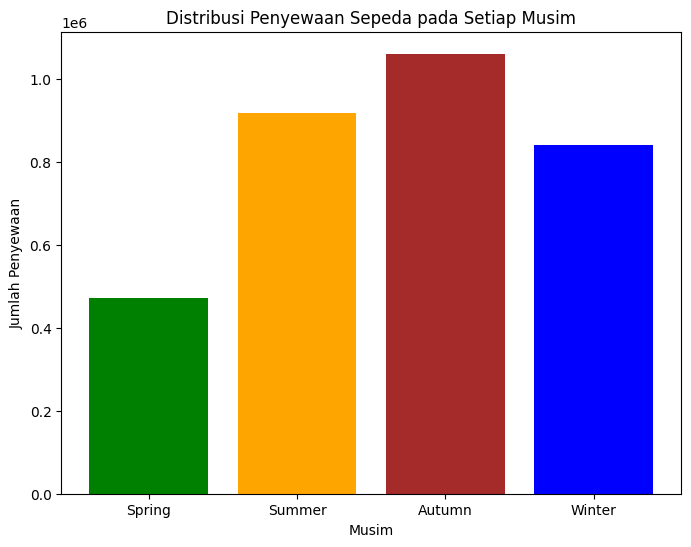

In [25]:
# Mengelompokkan data berdasarkan musim dan menghitung jumlah penyewaan pada setiap musim
season_counts = df_hour.groupby('season')['count'].sum()

# Menyusun label musim
season_labels = ['Spring', 'Summer', 'Autumn', 'Winter']

# Membuat diagram batang untuk visualisasi
plt.figure(figsize=(8, 6))
plt.bar(season_labels, season_counts, color=['green', 'orange', 'brown', 'blue'])
plt.title('Distribusi Penyewaan Sepeda pada Setiap Musim')
plt.xlabel('Musim')
plt.ylabel('Jumlah Penyewaan')
plt.show()

Berdasarkan analisis data, jumlah penyewaan sepeda tertinggi terjadi pada musim Autumn, diikuti oleh Summer, Winter, dan Spring. Kesimpulan ini didasarkan pada total penyewaan sepeda di setiap musim. Artinya, musim Autumn menjadi periode paling diminati untuk aktivitas bersepeda.

### Pertanyaan 2: Apakah ada jam tertentu dalam sehari di mana peminjaman sepeda cenderung tinggi?

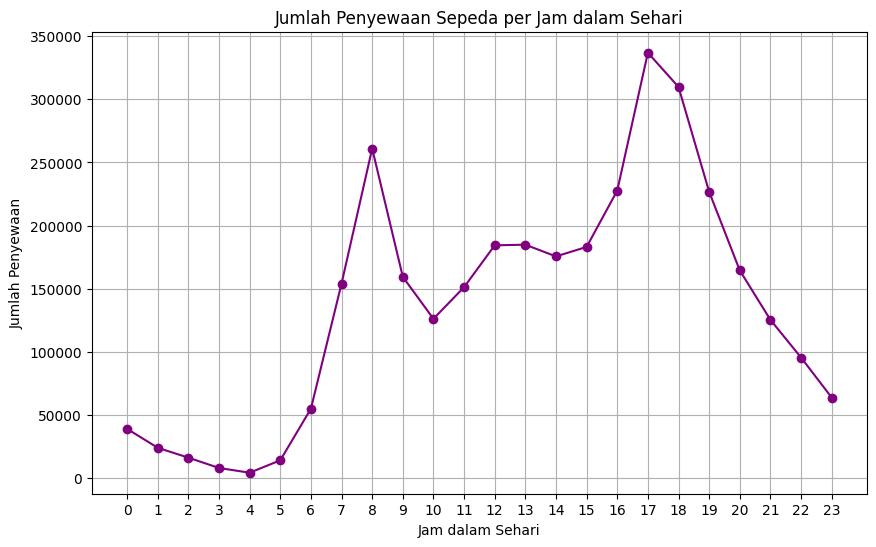

In [26]:
# Mengelompokkan data berdasarkan jam dalam sehari dan menghitung jumlah penyewaan pada setiap jam
hourly_counts = df_hour.groupby('hour')['count'].sum()

# Membuat diagram garis untuk visualisasi
plt.figure(figsize=(10, 6))
plt.plot(hourly_counts, marker='o', linestyle='-', color='purple')
plt.title('Jumlah Penyewaan Sepeda per Jam dalam Sehari')
plt.xlabel('Jam dalam Sehari')
plt.ylabel('Jumlah Penyewaan')
plt.xticks(range(24))
plt.grid(True)
plt.show()


Berdasarkan analisis data, terdapat tren bahwa penyewaan sepeda cenderung tinggi pada jam 17 (5 PM) dalam sehari, sementara jumlah penyewaan terendah terjadi pada jam 4 pagi.

### Pertanyaan 3: Apakah kondisi cuaca memengaruhi jumlah peminjaman sepeda?

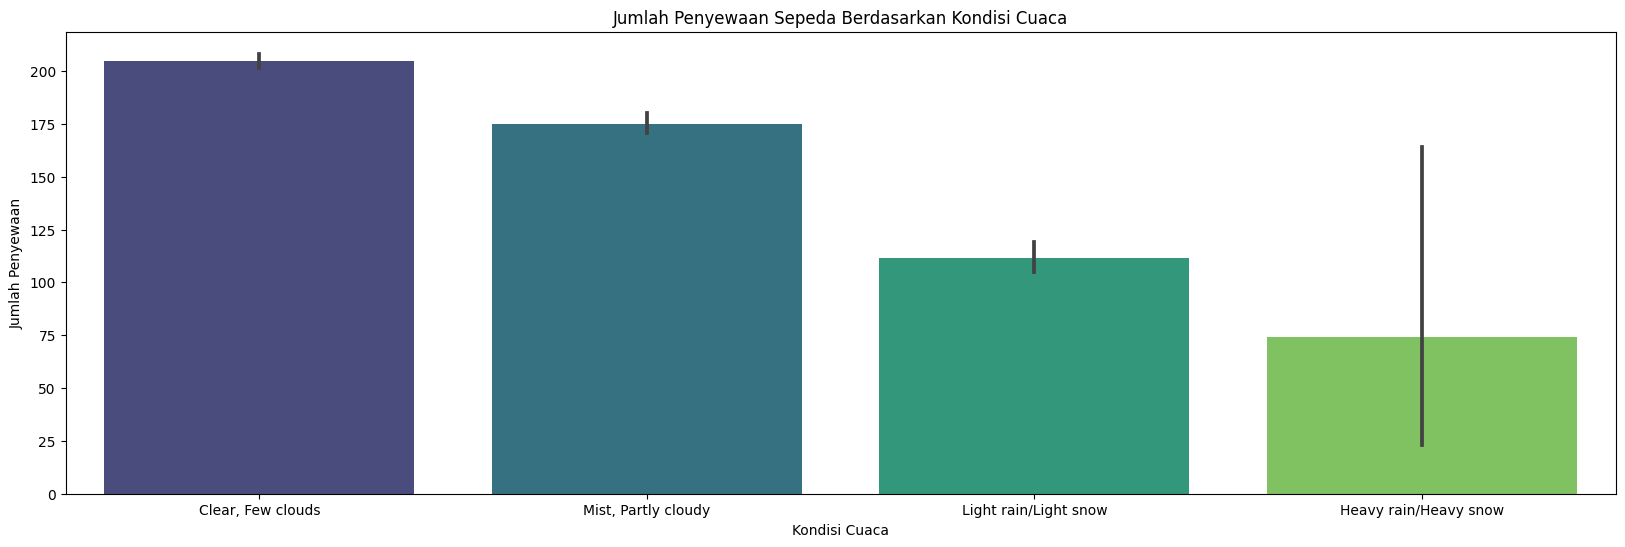

In [27]:
# Visualisasi jumlah penyewaan berdasarkan kondisi cuaca
plt.figure(figsize=(20, 6))
sns.barplot(x='weathersit', y='count', data=df_hour, palette='viridis')
plt.title('Jumlah Penyewaan Sepeda Berdasarkan Kondisi Cuaca')
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Jumlah Penyewaan')
plt.show()

Berdasarkan analisis data yang menunjukkan bahwa kondisi cuaca akan mempengaruhi penyewaan sepeda, cuaca cerah akan meningkatkan tingkat penyewaan sepeda dibandingkan cuaca lainnya.

### Pertanyaan 4: Apakah terdapat perbedaan dalam pola peminjaman sepeda antara tahun 2011 dan 2012? Jika ada, bagaimana peminjaman sepeda tersebut dibagi antara pengguna casual dan pengguna terdaftar?

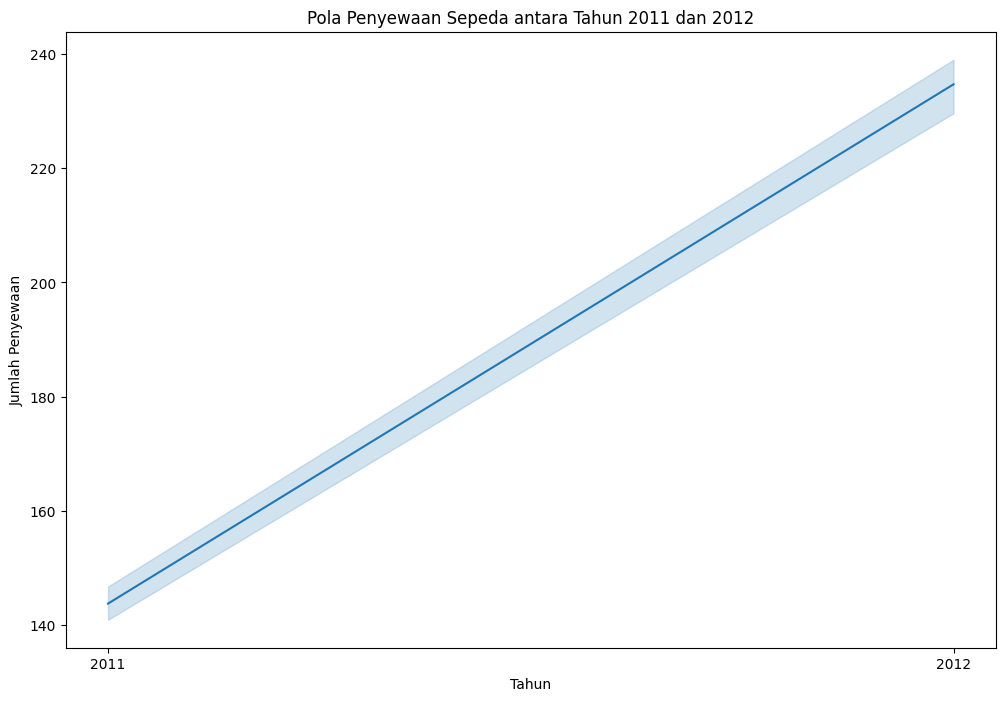

<Figure size 1200x800 with 0 Axes>

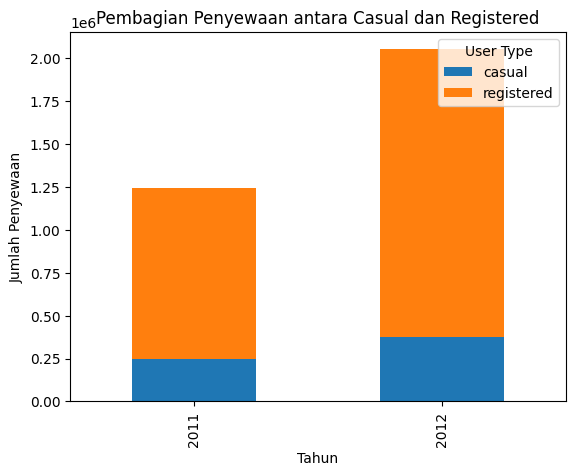

In [28]:
# Visualisasi Pola Penyewaan Sepeda antara Tahun 2011 dan 2012
plt.figure(figsize=(12, 8))
sns.lineplot(x='year', y='count', data=df_hour)
plt.title('Pola Penyewaan Sepeda antara Tahun 2011 dan 2012')
plt.xlabel('Tahun')
plt.ylabel('Jumlah Penyewaan')
plt.show()

# Visualisasi Pembagian Penyewaan antara Pengguna Casual dan Pengguna Terdaftar
plt.figure(figsize=(12, 8))
df_hour.groupby(['year'])[['casual', 'registered']].sum().plot(kind='bar', stacked=True)
plt.title('Pembagian Penyewaan antara Casual dan Registered')
plt.xlabel('Tahun')
plt.ylabel('Jumlah Penyewaan')
plt.legend(title='User Type', loc='upper right')
plt.show()

Tren penyewaan sepeda mengalami peningkatan antara tahun 2011 dan 2012. Peningkatan ini juga tercermin dalam jumlah penyewa casual dan terdaftar, dengan jumlah penyewa terdaftar lebih tinggi daripada penyewa casual.

## Conclusion

- Conclution pertanyaan 1:

  Penyewaan sepeda mencapai puncaknya pada musim gugur, diikuti oleh musim panas, musim dingin, dan musim semi.
- Conclution pertanyaan 2:
  
  Penyewaan sepeda cenderung tinggi pada jam 17 dalam sehari, sementara jumlah penyewaan terendah terjadi pada jam 4 pagi. Hal ini menunjukkan adanya pola tertentu dalam aktivitas peminjaman sepeda sepanjang hari, dengan puncak aktivitas terjadi pada sore hari.
- Conclution pertanyaan 3:

  Tingkat penyewaan sepeda dipengaruhi oleh kondisi cuaca, yang dapat dilihat dari perbedaan yang signifikan antara penyewaan pada cuaca cerah dengan cuaca lainnya, terutama saat cuaca hujan deras.
- Conclution pertanyaan 4:

  Pola penyewaan sepeda meningkat antara tahun 2011 dan 2012. Hal ini juga berlaku untuk penyewa casual dan registered, di mana jumlah penyewa registered tetap lebih tinggi secara signifikan.